In [1]:
# !pip install pandas scikit-learn
# !pip install kagglehub[pandas-datasets]
# !pip install seaborn

In this notebook, we load a book review dataset for making some recommendation based on similar behaviour of given scores to books. If 2 books have a similar user review behaviour, then they are identified as similar. Mathematically this is done by a cosine similarity matrix. 

As you will see in the following, there are nearly 3Million of reviews in the dataset, making the matrix very large and memry consuming. The ideal is to create a pivot table matrix with scikit learn, where lines are Book's Titles and columns are User's review rate. But with such data, an option is to build first a sparse matrix, less consuming and then compute the similarity cosine matrix. 

__How does cosine similarity deals with recommending a book ?__ 

The idea is the more 2 vectors are similar, the more their cosine similarity tends to 1. The matrix calculates the overlap between rating patterns of any pair of book's user review. When the algorithm evaluates the intersection of BookA with BookB, it identifies readers who awarded both books similar scores. If a same group of readers rated similar notes to the 2 books, the similarity of the books approaches 1. 

Conversely, if there is zero overlap in their readership, or if users who loved Book A consistently disliked Book B, the score drops toward 0. This approach completely ignores the actual content, genre, or summary of the books, relying entirely on the behavioral footprint and "wisdom of the crowd" left by the readers.


In [ ]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import kagglehub, os
import matplotlib.pyplot as plt 
import seaborn as sns
from scipy.sparse import csr_matrix

We will use the Amazon Books Review dataset which is available on Kaggle. It's an extract of Amazon review Dataset, containing product reviews and metadata from Amazon, spanning May 1996 - July 2014. It contains reviews of 212.404 unique books, from 1.008.973 unique users having rated books, leading to a total of 3.000.000 ratings. 

In [ ]:
# Amazon books review dataset 
path = kagglehub.dataset_download("mohamedbakhet/amazon-books-reviews")
print("Path to dataset files:", path)
for file in os.listdir(path):
    print(file)

C:\Users\yonau\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\yonau\.cache\kagglehub\datasets\mohamedbakhet\amazon-books-reviews\versions\1
books_data.csv
Books_rating.csv


In [4]:
books_data = pd.read_csv(os.path.join(path, "books_data.csv"))
rating_data = pd.read_csv(os.path.join(path, "Books_rating.csv"))

The books dataset contains 7 features: `Title`, `description`, `authors`, `image`, `previewLink`, `publisher`, `publishedDate`, `infoLink`, `categories`, `ratingsCount`. 

The rating dataset conains 10 features: `Id`, `Title`, `Price`, `User_id`, `profileName`, `review/helpfulness`, `review/score`, `review/time`, `review/summary`, `review/text`

In [5]:
print("Books data:")
books_data.head(3)

Books data:


,Title,description,authors,image,previewLink,publisher,publishedDate,infoLink,categories,ratingsCount
0,Its Only Art If Its Well Hung!,NaN,['Julie Strain'],http://books.google.com/books/content?id=DykPA...,http://books.google.nl/books?id=DykPAAAACAAJ&d...,NaN,1996,http://books.google.nl/books?id=DykPAAAACAAJ&d...,['Comics & Graphic Novels'],NaN
1,Dr. Seuss: American Icon,Philip Nel takes a fascinating look into the k...,['Philip Nel'],http://books.google.com/books/content?id=IjvHQ...,http://books.google.nl/books?id=IjvHQsCn_pgC&p...,A&C Black,2005-01-01,http://books.google.nl/books?id=IjvHQsCn_pgC&d...,['Biography & Autobiography'],NaN
2,Wonderful Worship in Smaller Churches,This resource includes twelve principles in un...,['David R. Ray'],http://books.google.com/books/content?id=2tsDA...,http://books.google.nl/books?id=2tsDAAAACAAJ&d...,NaN,2000,http://books.google.nl/books?id=2tsDAAAACAAJ&d...,['Religion'],NaN


In [ ]:
# Let's visualize the top 15 authors most reviewed (when unique author per book, else it's a list) 
# and the top 15 books best rated by users 
best_authors_count = books_data['authors'].value_counts().reset_index(name='Count').sort_values('Count', ascending=False).head(15)
best_books_count = rating_data.groupby('Title', as_index=False)['review/score'].sum().sort_values('review/score', ascending=False).head(15)

# Removing "[]"
best_authors_count['authors'] = best_authors_count['authors'].str.strip("[]'")

C:\Users\yonau\AppData\Local\Temp\ipykernel_21128\811734227.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(data=best_authors_count, x='authors', y='Count', palette='magma', ax=ax1)
C:\Users\yonau\AppData\Local\Temp\ipykernel_21128\811734227.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha='right', fontsize=6)
C:\Users\yonau\AppData\Local\Temp\ipykernel_21128\811734227.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(data=best_books_count, x='Title', y='review/score', palette='viridis', ax=ax2)
C:\Users\yonau\AppData\Local\Temp

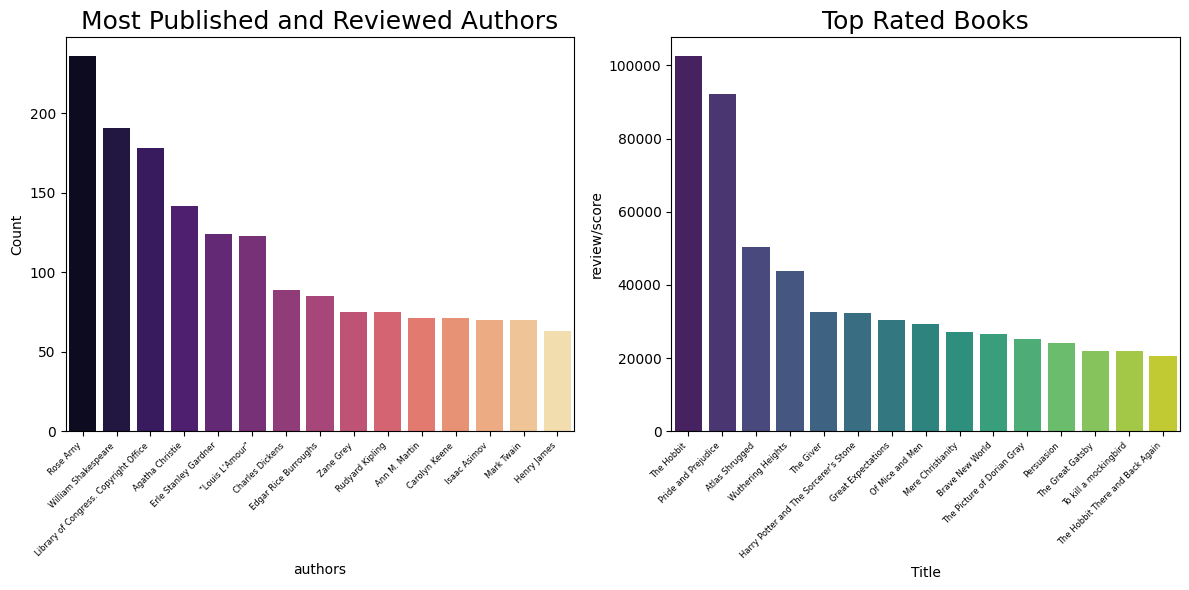

In [10]:
fig, (ax1,ax2) = plt.subplots(ncols=2, figsize=(12,6))

ax1 = sns.barplot(data=best_authors_count, x='authors', y='Count', palette='magma', ax=ax1)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha='right', fontsize=6)
ax1.set_title('Most Published and Reviewed Authors', size=18)

ax2 = sns.barplot(data=best_books_count, x='Title', y='review/score', palette='viridis', ax=ax2)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45, ha='right', fontsize=6)
ax2.set_title('Top Rated Books', size=18)

plt.tight_layout()

For a memory issue, we choose to lighter the dataset, by keeping active readers (more than 5 rated books) and famous books (more than 10 reviews). Also computing a sparse matrix allows keeping a large matrix of data. 

In [ ]:
def compute_cosine_similarity_sparse_matrix(col_name, rating_data): 
    """
    Computes the cosine similarity matrix for a 
    very large matrix using sparse matrix csr 
    from scipy.sparse, instead of pivot_table 
    from scikit learn. 
    """
    # Building matrix with user unique id, book title and given score to the book 
    ratescores = rating_data.dropna(subset=['User_id', 'Title', col_name]).copy()
    # Making data lighter on memory  
    # Keeping only active raters meaning users who rated more than 5 books 
    user_counts = ratescores['User_id'].value_counts()
    ratescores = ratescores[ratescores['User_id'].isin(user_counts[user_counts >= 5].index)]

    # Keeping books with + than 10 rates 
    book_counts = ratescores['Title'].value_counts()
    ratescores = ratescores[ratescores['Title'].isin(book_counts[book_counts >= 10].index)]

    # sparse matrix works with index numbers 
    # Convert indexes into numbers 
    ratescores['user_index'] = ratescores['User_id'].astype('category')
    ratescores['title_index'] = ratescores['Title'].astype('category')

    user_codes = ratescores['user_index'].cat.codes # retrieve previous given indexes
    title_codes = ratescores['title_index'].cat.codes

    # pivot matrix with sparsity - avoiding heavy data alocation in RAM 
    sparse_matrix = csr_matrix((
        ratescores[col_name], 
        (title_codes, user_codes)
    ))

    # Cosine similarity computation
    similarity_matrix = cosine_similarity(sparse_matrix)

    return similarity_matrix, ratescores

similarity_matrix_scores, ratescores = compute_cosine_similarity_sparse_matrix(col_name='review/score', rating_data=rating_data)

In [46]:
similarity_matrix_scores.shape

(14251, 14251)

In [ ]:
def recommend(book_title, ratescores_df, sim_matrix, top_n=5):
    """
    Recommends top books for a given title, based on similar given scores. 
    """
    # retrieve previous given indexes
    unique_titles = ratescores_df['Title'].astype('category').cat.categories
    if book_title not in unique_titles:
        return f"The book'{book_title}'has not enough reviews or has been filtred and does not appear in the database currently."

    idx = unique_titles.get_loc(book_title) # get the book location
    
    sim_scores = list(enumerate(sim_matrix[idx])) # get the line corresponding to this book in the similarity matrix 
    
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True) # score order 
    
    sim_scores = sim_scores[1:top_n+1] # index 0 is the book itself 

    book_indices = [i[0] for i in sim_scores]
    recommendations = [unique_titles[i] for i in book_indices] # reassociate book titles 
    
    return recommendations

recommend("My Life", ratescores, similarity_matrix_scores)

['Sinatra: The Life',
 'I, Tina',
 "1,000 Places to See Before You Die: A Traveler's Life List",
 'Raging Bull',
 'My Autobiography']

In [ ]:
recommend("1984", ratescores, similarity_matrix_scores)

['Nineteen Eighty-four',
 'George Orwell 1984',
 'ANIMAL FARM - A Fairy Story (Time Reading Program Special Edition)',
 'Animal Farm',
 'Animal Farm (Signet Classics, CT304)']